In [1]:
import pandas as pd 

data = {
    "study_time": [2, 3, 4, 5, 6, 7, 8],
    "exam_score": [50, 55, 60, 65, 70, 78, 85]
}

df = pd.DataFrame(data) 

print(df.corr(method="pearson"))

            study_time  exam_score
study_time    1.000000    0.995117
exam_score    0.995117    1.000000


In [2]:
print(df.corr(method="spearman"))


            study_time  exam_score
study_time         1.0         1.0
exam_score         1.0         1.0


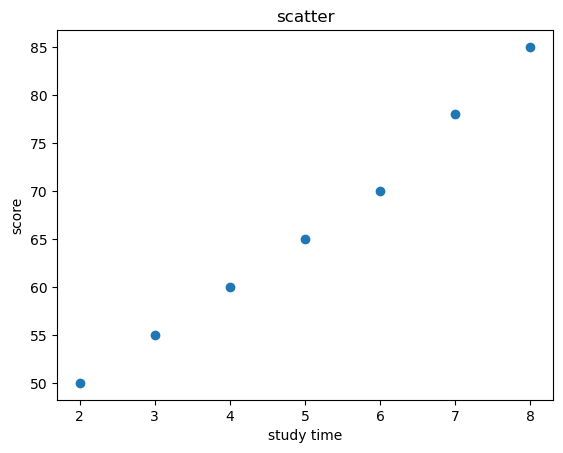

In [3]:
import matplotlib.pyplot as plt

plt.scatter(df["study_time"], df["exam_score"])
plt.xlabel("study time")
plt.ylabel("score")
plt.title("scatter")
plt.show()

In [4]:
import statsmodels.api as sm

X = df["study_time"]
y = df["exam_score"]

X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             exam_score   R-squared:                       0.990
Model:                            OLS   Adj. R-squared:                  0.988
Method:                 Least Squares   F-statistic:                     508.3
Date:                Fri, 18 Sep 2026   Prob (F-statistic):           3.19e-06
Time:                        11:19:43   Log-Likelihood:                -10.854
No. Observations:                   7   AIC:                             25.71
Df Residuals:                       5   BIC:                             25.60
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         37.3929      1.373     27.225      0.0

C:\Users\isabe\anaconda3\Lib\site-packages\statsmodels\stats\stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 7 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


expected score for 6 hours of study: 106.50score


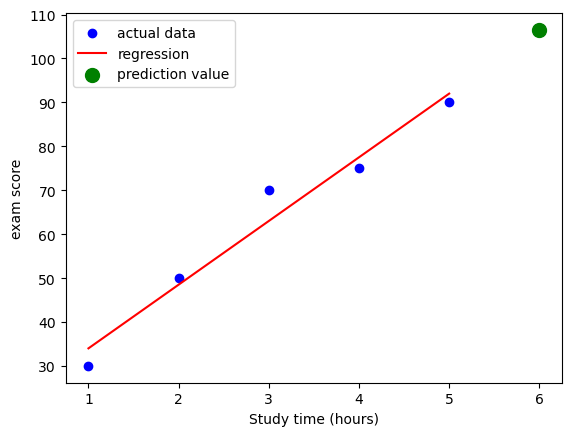

In [11]:
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.linear_model import LinearRegression

X = np.array([[1], [2], [3], [4], [5]])
y = np.array([30, 50, 70, 75, 90]) 

model = LinearRegression() 
model.fit(X, y) 

X_new = np.array([[6]])
y_pred = model.predict(X_new)
print(f"expected score for 6 hours of study: {y_pred[0]:.2f}score") 

plt.scatter(X, y, color="blue", label="actual data")
plt.plot(X, model.predict(X), color="red", label="regression")
plt.scatter(X_new, y_pred, color="green", s=100, label="prediction value") 
plt.xlabel("Study time (hours)")
plt.ylabel("exam score") 
plt.legend()
plt.show() 

In [10]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import accuracy_score, classification_report 

iris = load_iris() 
X = iris.data 
y = iris.target 

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

model = LogisticRegression(max_iter=200) 
model.fit(X_train, y_train) 

y_pred = model.predict(X_test) 

print("accuracy:", accuracy_score(y_test, y_pred))
print("classification report:", classification_report(y_test, y_pred, target_names=iris.target_names))

new_data = [[5.0, 3.5, 1.3, 0.2]]
prediction = model.predict(new_data)
print("new data predition results:", iris.target_names[prediction][0])

accuracy: 1.0
classification report:               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

new data predition results: setosa


C:\Users\isabe\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Accuracy: 0.9333333333333333


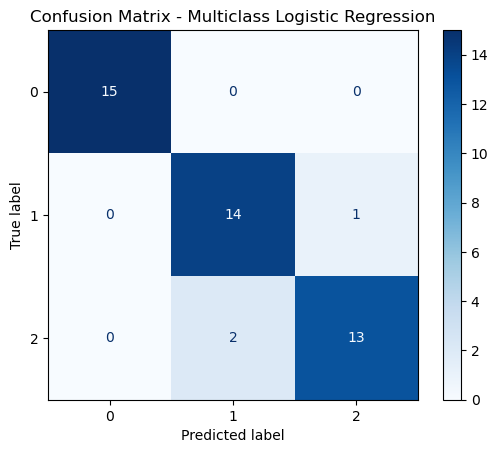

Probability by class for the first 5 samples [[1.89009605e-06 3.23277313e-02 9.67670379e-01]
 [4.52959869e-03 7.63798449e-01 2.31671952e-01]
 [9.23750275e-04 5.05594174e-01 4.93482076e-01]
 [5.07028151e-03 6.61724496e-01 3.33205223e-01]
 [1.69317694e-03 4.09580753e-01 5.88726070e-01]]


In [12]:
import matplotlib.pyplot as plt 
from sklearn.datasets import load_iris 
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split 
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay 

#data load 
X, y = load_iris(return_X_y=True) 

#learning/test segmentation 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

#multiclass logisitic regression (softmax) 
model = LogisticRegression(multi_class="multinomial", solver="lbfgs", max_iter=200) 
model.fit(X_train, y_train) 

#prediction 
y_pred = model.predict(X_test) 

#accuracy evaluation 
print("Accuracy:", accuracy_score(y_test, y_pred))

#confusion matrix visualisation 
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_) 
disp.plot(cmap="Blues") 
plt.title("Confusion Matrix - Multiclass Logistic Regression") 
plt.show() 

probs = model.predict_proba(X_test[:5])
print("Probability by class for the first 5 samples", probs)



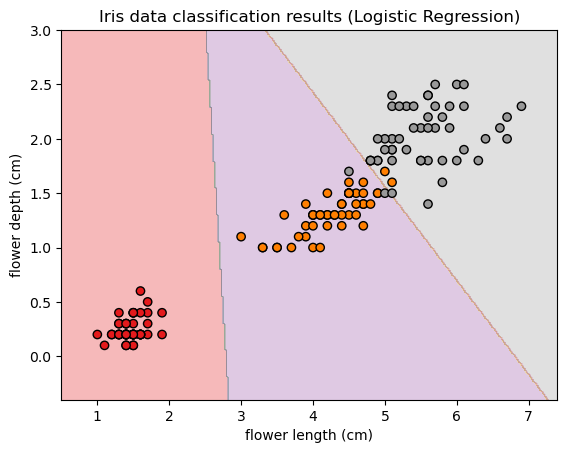

In [14]:
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris 
from sklearn.linear_model import LogisticRegression 

#load data 
iris = load_iris()
X = iris.data[:, 2:4]
y = iris.target 

#model learning 
model = LogisticRegression(max_iter=200) 
model.fit(X, y) 

#draw classification boundary line 
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5 
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), 
                     np.linspace(y_min, y_max, 300))
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape) 

#visualisation 
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set1) 
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor='k', cmap=plt.cm.Set1) 
plt.xlabel("flower length (cm)")
plt.ylabel("flower depth (cm)")
plt.title("Iris data classification results (Logistic Regression)") 
plt.show()


petal length (cm) values:  5
petal width (cm) values:  2


prediction result: virginica


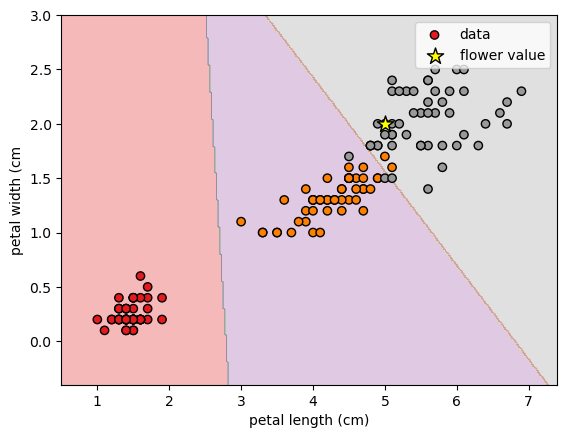

In [18]:
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris 
from sklearn.linear_model import LogisticRegression 

#load data
iris = load_iris() 
X = iris.data[:, 2:4] #petal length and width 
y = iris.target 
target_names = iris.target_names 

#model learning 
model = LogisticRegression(max_iter=200) 
model.fit(X, y) 

#prepare classification boundary (분류 경계산 준비) 
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5 
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), 
                     np.linspace(y_min, y_max, 300))
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape) 

#used inputs 
petal_length = float(input("petal length (cm) values: "))
petal_width = float(input("petal width (cm) values: "))

#prediction 
new_point = np.array([[petal_length, petal_width]]) 
prediction = model.predict(new_point)[0]
print(f"prediction result: {target_names[prediction]}") 

#visualisation 
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set1)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor="k", cmap=plt.cm.Set1, label="data") 
plt.scatter(petal_length, petal_width, c="yellow", edgecolor="black", s=150, marker="*", label="flower value") 
plt.xlabel("petal length (cm)") 
plt.ylabel("petal width (cm") 
plt.legend() 
plt.show()


In [20]:
%%writefile app.py
import streamlit as st 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.datasets import load_iris 
from sklearn.linear_model import LogisticRegression

#load dataset 
iris = load_iris() 
X = iris.data[:, 2:4] #petal length and width 
y = iris.target 
target_names = iris.target_names 

#model learning 
model = LogisticRegression(max_iter=200) 
model.fit(X, y) 

#streamlist UI 
st.title("Iris flower classification (Logistic Regression)") 
st.write("By entering the petal length and width, what species does it predict?")

#enter slider 
petal_length = st.slider("petal length (cm)", float(X[:,0].min()), float(X[:,0].max()), 5.0) 
petal_width = st.slider("petal width (cm)", float(X[:,1].min()), float(X[:,1].max()), 1.5)

#prediction 
new_point = np.array([[petal_length, petal_width]]) 
prediction = model.predict(new_point)[0]
st.subheader(f"prediction results: **{target_names[prediction]}**")

#graph visualisation 
x_min, x_max = X[:, 0].min() - 0.5, X[:,0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:,1].max() + 0.5 
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), 
                     np.linspace(y_min, y_max, 300)) 
Z = model.predict(np.c_[xx.ravel(), yy.ravel()]) 
Z = Z.reshape(xx.shape) 

fig, ax = plt.subplots() 
ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set1) 
ax.scatter(X[:,0], X[:,1], c=y, edgecolor="k", cmap=plt.cm.Set1, label="data") 
ax.scatter(petal_length, petal_width, c="yellow", edgecolor="black", s=150, marker="*", label="flower value") 
ax.set_xlabel("petal length (cm)") 
ax.set_ylabel("petal width (cm)") 
ax.set_title("Iris classification results") 
ax.legend() 

st.pyplot(fig) 



Writing app.py


In [24]:
%pip install gradio

  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------- ----------------------------- 8.4/31.4 MB 47.5 MB/s eta 0:00:01
   --------------------------- ------------ 21.2/31.4 MB 53.9 MB/s eta 0:00:01
   ---------------------------------------  31.2/31.4 MB 51.7 MB/s eta 0:00:01
   ---------------------------------------- 31.4/31.4 MB 41.2 MB/s  0:00:00
   ---------------------------------------- 0.0/842.9 kB ? eta -:--:--
   ---------------------------------------- 842.9/842.9 kB 18.5 MB/s  0:00:00
Using cached click-8.5.0-py3-none-any.whl (125 kB)
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 4.0/4.0 MB 37.8 MB/s  0:00:00

   ----------------------------------------  0/18 [pydub]
   ------ ---------------------------------  3/18 [python-multipart]
   -------- -------------------------------  4/18 [orjson]
   ----------- -----------

In [27]:
import gradio as gr 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.datasets import load_iris 
from sklearn.linear_model import LogisticRegression 

#load data 
iris = load_iris() 
X = iris.data[:, 2:4] #using only petal length and width 
y = iris.target 
target_names = iris.target_names 

#model learning 
model = LogisticRegression(max_iter=200)
model.fit(X, y) 

#predict + visualisation function 
def predict_and_plot(petal_length, petal_width): 
    #predict 
    new_point = np.array([[petal_length, petal_width]]) 
    prediction = model.predict(new_point)[0]
    result = f"predict result: **{target_names[prediction]}**" 

    #prepare graph 
    x_min, x_max = X[:, 0].min() - 0.5, X[:,0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:,1].max() + 0.5 
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), 
                     np.linspace(y_min, y_max, 300)) 
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]) 
    Z = Z.reshape(xx.shape) 

    fig, ax = plt.subplots() 
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set1) 
    ax.scatter(X[:, 0], X[:, 1], c=y, edgecolor="k", cmap=plt.cm.Set1, label="data")  
    ax.scatter(petal_length, petal_width, c="yellow", edgecolor="black", s=150, marker="*", label = "flower value")
    ax.set_xlabel("petal length (cm)") 
    ax.set_ylabel("petal width (cm)") 
    ax.set_title("Iris classification results (Logistic Regression)")
    ax.legend() 

    return result, fig 

#Gradio interface 
interface = gr.Interface(
    fn=predict_and_plot, 
    inputs=[
        gr.Slider(minimum=float(X[:,0].min()), maximum=float(X[:,0].max()), value=5.0, label="petal length (cm)"),
        gr.Slider(minimum=float(X[:,1].min()), maximum=float(X[:,1].max()), value=1.5, label="petal width (cm)")
    ],
    outputs=["markdown", "plot"],
    title="Iris flower classification",
    description="By entering the petal length and width, what type does it predict?"
)

interface.launch() 

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [29]:
import os 
os.environ["OMP_NUM_THREADS"] = "1"

C:\Users\isabe\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


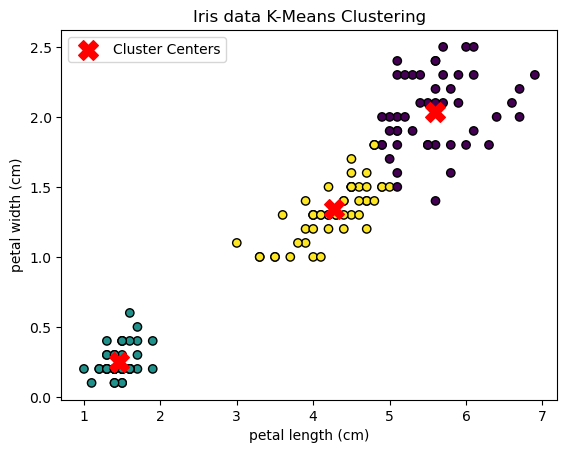

In [30]:
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris 
from sklearn.cluster import KMeans

#upload data 
iris = load_iris() 
X = iris.data[:, 2:4]

#KMeans clustering (3 times split group) 
kmeans = KMeans(n_clusters=3, random_state=42) 
kmeans.fit(X) 
labels = kmeans.labels_ 
centers = kmeans.cluster_centers_ 

#visualisation 
plt.scatter(X[:,0], X[:,1], c=labels, cmap="viridis", marker="o", edgecolor="k") 
plt.scatter(centers[:,0], centers[:,1], c="red", s=200, marker="X", label="Cluster Centers") 
plt.xlabel("petal length (cm)") 
plt.ylabel("petal width (cm)") 
plt.title("Iris data K-Means Clustering") 
plt.legend()
plt.show() 

In [3]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    confusion_matrix,
    accuracy_score,
)
from threadpoolctl import threadpool_limits


def purity_score(y_true, y_pred):
    # Rows: clusters; columns: true labels
    cm = confusion_matrix(y_pred, y_true)
    return np.sum(np.max(cm, axis=1)) / np.sum(cm)


def map_cluster_labels(y_true, y_pred, k):
    cm = confusion_matrix(y_pred, y_true)
    mapping = {}

    for cluster_id in range(k):
        mapping[cluster_id] = np.argmax(cm[cluster_id])

    y_mapped = np.array([mapping[label] for label in y_pred])
    return y_mapped, mapping


# Data: petal length and petal width
iris = load_iris()
X = iris.data[:, 2:4]
y_true = iris.target
target_names = iris.target_names

# Fit KMeans with one thread
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

with threadpool_limits(limits=1):
    kmeans.fit(X)

y_kmeans = kmeans.labels_
centers = kmeans.cluster_centers_

# Performance metrics
ari = adjusted_rand_score(y_true, y_kmeans)
nmi = normalized_mutual_info_score(y_true, y_kmeans)
purity = purity_score(y_true, y_kmeans)

print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")
print(f"Purity: {purity:.4f}")

# Map each cluster to its majority true label
y_mapped, mapping = map_cluster_labels(y_true, y_kmeans, k)
accuracy_after_mapping = accuracy_score(y_true, y_mapped)

print(f"Accuracy after mapping: {accuracy_after_mapping:.4f}")

Adjusted Rand Index (ARI): 0.8857
Normalized Mutual Information (NMI): 0.8642
Purity: 0.9600
Accuracy after mapping: 0.9600


Adjusted Rand Index (ARI): 0.8857
Normalized Mutual Information (NMI): 0.8642
Purity: 0.9600
Accuracy after mapping: 0.9600
Cluster -> mapped true-label: {0: np.int64(2), 1: np.int64(0), 2: np.int64(1)}


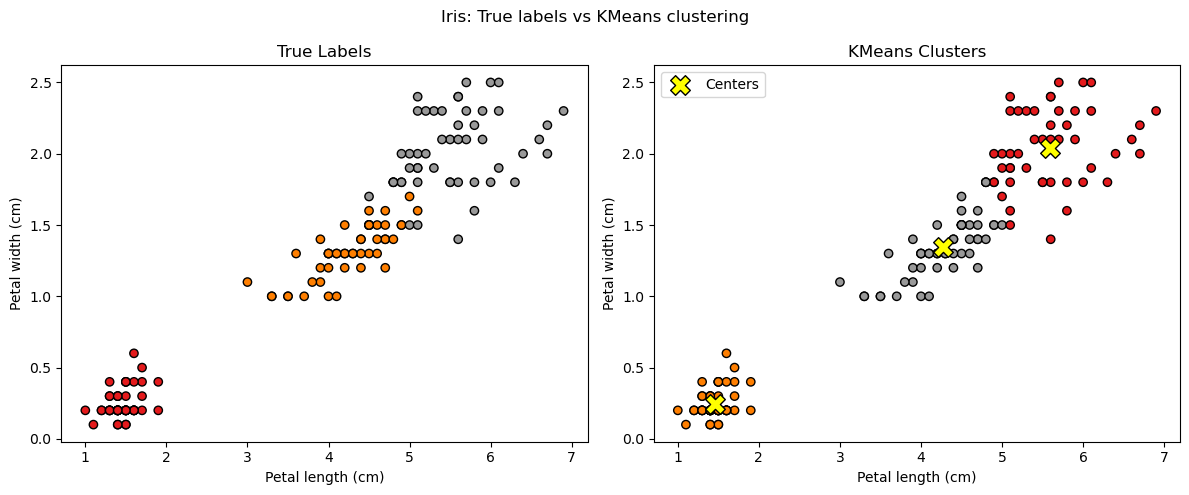

In [6]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    confusion_matrix,
    accuracy_score,
)
from threadpoolctl import threadpool_limits


def purity_score(y_true, y_pred):
    # Rows: clusters; columns: true labels
    cm = confusion_matrix(y_pred, y_true)
    return np.sum(np.max(cm, axis=1)) / np.sum(cm)


def map_cluster_labels(y_true, y_pred, k):
    cm = confusion_matrix(y_pred, y_true)
    mapping = {}

    for cluster_id in range(k):
        mapping[cluster_id] = np.argmax(cm[cluster_id])

    y_mapped = np.array([mapping[label] for label in y_pred])
    return y_mapped, mapping


# Data: petal length and petal width
iris = load_iris()
X = iris.data[:, 2:4]
y_true = iris.target
target_names = iris.target_names

# Fit KMeans with one thread
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

with threadpool_limits(limits=1):
    kmeans.fit(X)

y_kmeans = kmeans.labels_
centers = kmeans.cluster_centers_

# Performance metrics
ari = adjusted_rand_score(y_true, y_kmeans)
nmi = normalized_mutual_info_score(y_true, y_kmeans)
purity = purity_score(y_true, y_kmeans)

print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")
print(f"Purity: {purity:.4f}")

# Map each cluster to its majority true label
y_mapped, mapping = map_cluster_labels(y_true, y_kmeans, k)
accuracy_after_mapping = accuracy_score(y_true, y_mapped)

print(f"Accuracy after mapping: {accuracy_after_mapping:.4f}")
print("Cluster -> mapped true-label:", mapping) 

#visualisation 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

#real label 
axes[0].scatter(X[:, 0], X[:, 1], c=y_true, edgecolor='k', cmap=plt.cm.Set1) 
axes[0].set_title("True Labels") 
axes[0].set_xlabel("Petal length (cm)") 
axes[0].set_ylabel("Petal width (cm)") 

#cluster label

axes[1].scatter(X[:, 0], X[:, 1], c=y_kmeans, edgecolor='k', cmap=plt.cm.Set1) 
axes[1].scatter(centers[:,0], centers[:,1], c='yellow', edgecolor='black', 
                s=200, marker='X', label='Centers') 
axes[1].set_title("KMeans Clusters") 
axes[1].set_xlabel("Petal length (cm)") 
axes[1].set_ylabel("Petal width (cm)") 
axes[1].legend() 

plt.suptitle("Iris: True labels vs KMeans clustering") 
plt.tight_layout() 
plt.show() 